# Portfolio selection with QAOA in Qiskit
Choosing exactly *K* of *n* stocks is a constrained binary optimisation problem. This notebook solves it with **penalty QAOA** and with a **constraint-preserving QAOA** (Dicke-state start + XY ring mixer, no penalty term), and checks every result against brute force, an independent NumPy simulator, and classical heuristics (greedy, simulated annealing).

**Author:** Mitali Jain &nbsp;|&nbsp; **Stack:** Qiskit, NumPy, SciPy, Matplotlib

**Contents**
1. Problem and classical reference &nbsp;
2. QUBO to Ising Hamiltonian &nbsp;
3. Exact NumPy QAOA simulator
4. Qiskit circuit and cross-validation &nbsp;
5. Baseline experiment (6 stocks): depth and penalty sweeps
6. Sampling with Qiskit &nbsp;
7. Scaling up (12 stocks) with a constraint-preserving QAOA &nbsp;
8. Limitations and future work

**Origin and credits.** Built for the Qiskit Fall Fest 2026 hackathon (IIIT-Delhi), Track 2. The problem statement and data generator come from the challenge (tutorial by Benjamin Tirado; challenge adapted from the BasQ hackathon prompt by Angel Rodriguez, Benjamin Tirado and Miguel Angel Jimenez; text CC BY 4.0, code Apache 2.0). All other code and analysis in this notebook are my own work with the AI assistance noted below.

**AI assistance.** I used Claude (Anthropic) as a coding and writing assistant. It helped draft the notebook structure, the QUBO-to-Ising derivation, the exact NumPy QAOA simulator. I ran the full notebook myself and checked that the Qiskit circuits match the independent NumPy simulator. The problem statement and data generator come from the Qiskit Fall Fest 2026 challenge, as credited above.

**How to run.** `pip install -r requirements.txt`, then *Run All* (a few minutes on a laptop). Everything runs on simulators; no IBM account is needed. Sections marked **[Qiskit]** need Qiskit; the rest is plain NumPy/SciPy and doubles as an independent reference. Figures are also saved to `figures/`.

## 0. Setup

In [4]:
import os
import itertools
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

SEED = 2026
FIG = "figures"; os.makedirs(FIG, exist_ok=True)          # plots are saved here for the README
np.set_printoptions(precision=4, suppress=True)

## 1. The problem and its classical reference
Pick exactly `K` of `n` stocks minimising  
$C(x) = q\,x^\top\Sigma x - \mu^\top x + \lambda\,(\sum_i x_i - K)^2$.

**Bit convention (important):** qubit `i` is stock `i`. Integer index `k` encodes `x_i = (k >> i) & 1`, i.e. qubit 0 is the least-significant bit, the same as Qiskit's statevector ordering. Qiskit *bitstrings* print with qubit 0 on the **right**, so we reverse them when decoding samples.

In [5]:
def make_problem(n=6, K=3, q=0.5, seed=SEED):
    rng = np.random.default_rng(seed)          # same data generator as the challenge statement
    mu = rng.uniform(0.05, 0.25, n)
    A = rng.normal(0, 0.1, (n, n))
    sigma = A @ A.T
    return dict(n=n, K=K, q=q, mu=mu, sigma=sigma)

def all_bitstrings(n):
    ks = np.arange(2 ** n)
    return ((ks[:, None] >> np.arange(n)) & 1).astype(float)      # row k -> x

def all_costs(P, lam):
    X = all_bitstrings(P["n"])
    C = (P["q"] * np.einsum("ki,ij,kj->k", X, P["sigma"], X)
         - X @ P["mu"] + lam * (X.sum(1) - P["K"]) ** 2)
    return C, X

P = make_problem(6, 3)
n, K = P["n"], P["K"]
print("mu =", P["mu"])

mu = [0.0858 0.178  0.1435 0.1241 0.121  0.2081]


In [6]:
def classical_reference(P, lam):
    C, X = all_costs(P, lam)
    valid = X.sum(1) == P["K"]
    kbest = np.where(valid)[0][np.argmin(C[valid])]                 # best *valid* portfolio
    return dict(C=C, X=X, valid=valid, Cmin=C.min(), Cmax=C.max(),
                Cmin_valid=C[valid].min(), Cmax_valid=C[valid].max(),
                kbest=int(kbest), xbest=X[kbest].astype(int),
                global_min_is_valid=bool(valid[np.argmin(C)]))

LAM = 0.5                      # default penalty; swept in section 5
ref = classical_reference(P, LAM)
print(f"valid portfolios: {ref['valid'].sum()} (expect 20)")
print(f"Cmin={ref['Cmin']:.4f}  Cmax={ref['Cmax']:.4f}  best valid cost={ref['Cmin_valid']:.4f}")
print("best valid portfolio x =", ref["xbest"], "-> stocks", np.where(ref["xbest"])[0])

valid portfolios: 20 (expect 20)
Cmin=-0.5030  Cmax=4.5000  best valid cost=-0.5030
best valid portfolio x = [0 1 1 0 0 1] -> stocks [1 2 5]


## 2. From $C(x)$ to an Ising Hamiltonian
Using $x_i^2 = x_i$ the cost is a QUBO: linear terms $a_i = q\Sigma_{ii} - \mu_i + \lambda(1-2K)$, pair terms $b_{ij} = 2q\Sigma_{ij} + 2\lambda$ for $i<j$, constant $\lambda K^2$.  
Substituting $x_i = (1 - Z_i)/2$ gives $C = \text{offset} + \sum_i h_i Z_i + \sum_{i<j} J_{ij} Z_i Z_j$ with  
$h_i = -a_i/2 - \tfrac14\sum_{j\ne i} b_{ij}$, $\;J_{ij} = b_{ij}/4$, $\;\text{offset} = \lambda K^2 + \tfrac12\sum_i a_i + \tfrac14\sum_{i<j} b_{ij}$.

In [7]:
def ising_coeffs(P, lam):
    n, K, q, mu, sigma = P["n"], P["K"], P["q"], P["mu"], P["sigma"]
    a = q * np.diag(sigma) - mu + lam * (1 - 2 * K)
    b = 2 * q * sigma + 2 * lam
    h = -a / 2.0
    J, offset = {}, lam * K ** 2 + a.sum() / 2.0
    for i in range(n):
        for j in range(i + 1, n):
            J[(i, j)] = b[i, j] / 4.0
            h[i] -= b[i, j] / 4.0
            h[j] -= b[i, j] / 4.0
            offset += b[i, j] / 4.0
    return h, J, offset

def ising_diag(n, h, J, offset):
    ks = np.arange(2 ** n)
    Z = 1 - 2 * ((ks[:, None] >> np.arange(n)) & 1)           # |0> -> +1, |1> -> -1
    d = np.full(2 ** n, offset, float) + Z @ h
    for (i, j), v in J.items():
        d += v * Z[:, i] * Z[:, j]
    return d

h, J, offset = ising_coeffs(P, LAM)
diag = ising_diag(n, h, J, offset)                 # diagonal of the cost Hamiltonian (incl. offset)
err = np.abs(diag - ref["C"]).max()
print("max |Ising - C(x)| over all 2^n bitstrings:", err)
assert err < 1e-10

max |Ising - C(x)| over all 2^n bitstrings: 6.661338147750939e-16


## 3. Exact NumPy QAOA simulator (independent reference)
The cost is diagonal, so QAOA can be simulated exactly in a few lines. We use it (a) for fast parameter sweeps and (b) to cross-check Qiskit's result in section 4.  
Ansatz: $|+\rangle^{n}$, then $p$ layers of $e^{-i\gamma_l H_C}$ and $e^{-i\beta_l \sum_i X_i}$.

In [8]:
def qaoa_state(n, diag, gammas, betas):
    psi = np.full(2 ** n, 1 / np.sqrt(2 ** n), complex)
    for g, b in zip(gammas, betas):
        psi = psi * np.exp(-1j * g * diag)
        U = np.array([[np.cos(b), -1j * np.sin(b)], [-1j * np.sin(b), np.cos(b)]])   # RX(2b)
        t = psi.reshape((2,) * n)
        for ax in range(n):
            t = np.moveaxis(np.tensordot(U, t, axes=([1], [ax])), 0, ax)
        psi = t.reshape(-1)
    return psi

def np_energy(n, diag, params):
    p = len(params) // 2
    psi = qaoa_state(n, diag, params[:p], params[p:])
    return float(np.real(np.sum(np.abs(psi) ** 2 * diag)))

def optimise(n, diag, p, restarts=20, maxiter=400, seed=0):
    rng = np.random.default_rng(seed)
    best = None
    for _ in range(restarts):
        x0 = rng.uniform(0, np.pi / 2, 2 * p)
        res = minimize(lambda t: np_energy(n, diag, t), x0, method="COBYLA", options={"maxiter": maxiter})
        if best is None or res.fun < best.fun:
            best = res
    return best.x, best.fun

def metrics(P, lam, params):
    ref = classical_reference(P, lam)
    n = P["n"]; p = len(params) // 2
    h, J, off = ising_coeffs(P, lam)
    diag = ising_diag(n, h, J, off)
    prob = np.abs(qaoa_state(n, diag, params[:p], params[p:])) ** 2
    E = float(prob @ diag)
    r = (ref["Cmax"] - E) / (ref["Cmax"] - ref["Cmin"])           # ratio as defined in the challenge
    pf = float(prob[ref["valid"]].sum())
    Ef = float(prob[ref["valid"]] @ ref["C"][ref["valid"]] / pf) if pf > 0 else np.nan
    r_valid = (ref["Cmax_valid"] - Ef) / (ref["Cmax_valid"] - ref["Cmin_valid"])   # restricted to valid portfolios
    return dict(E=E, r=r, p_feasible=pf, p_best=float(prob[ref["kbest"]]), r_valid=r_valid)

## 4. [Qiskit] Build the QAOA circuit and validate it against the NumPy reference
Qubit `i` = stock `i`. $e^{-i\gamma J ZZ}$ is `rzz(2*gamma*J)`, $e^{-i\gamma h Z}$ is `rz(2*gamma*h)`, $e^{-i\beta X}$ is `rx(2*beta)`.

In [9]:
from qiskit import QuantumCircuit
from qiskit.circuit import ParameterVector
from qiskit.quantum_info import SparsePauliOp
from qiskit.primitives import StatevectorEstimator, StatevectorSampler
import qiskit; print("qiskit", qiskit.__version__)

qiskit 2.2.3


In [10]:
def build_cost_operator(n, h, J):
    terms = [("Z", [i], float(h[i])) for i in range(n)]
    terms += [("ZZ", [i, j], float(v)) for (i, j), v in J.items()]
    return SparsePauliOp.from_sparse_list(terms, num_qubits=n)      # excludes the constant offset

def build_qaoa(n, h, J, p):
    gam, bet = ParameterVector("gam", p), ParameterVector("bet", p)
    qc = QuantumCircuit(n)
    qc.h(range(n))
    for l in range(p):
        for (i, j), v in J.items():
            qc.rzz(2 * gam[l] * float(v), i, j)
        for i in range(n):
            qc.rz(2 * gam[l] * float(h[i]), i)
        for i in range(n):
            qc.rx(2 * bet[l], i)
    return qc, gam, bet

def bind(qc, gam, bet, params):
    p = len(params)//2
    return qc.assign_parameters({**dict(zip(gam, params[:p])), **dict(zip(bet, params[p:]))})

H = build_cost_operator(n, h, J)
assert np.allclose(np.real(np.diag(H.to_matrix())) + offset, ref["C"]), "Pauli operator != C(x)"
print("Pauli operator matches C(x) on all bitstrings.")

Pauli operator matches C(x) on all bitstrings.


In [11]:
estimator = StatevectorEstimator()
def qiskit_energy(qc, gam, bet, params, H, offset):
    ev = estimator.run([(bind(qc, gam, bet, params), H)]).result()[0].data.evs
    return float(ev) + offset

# cross-check Qiskit against the NumPy simulator at random angles
rng = np.random.default_rng(1)
for p in (1, 2, 3):
    qc, gam, bet = build_qaoa(n, h, J, p)
    prm = rng.uniform(0, np.pi, 2 * p)
    e_q, e_np = qiskit_energy(qc, gam, bet, prm, H, offset), np_energy(n, diag, prm)
    print(f"p={p}: qiskit={e_q:.8f}  numpy={e_np:.8f}  diff={abs(e_q - e_np):.2e}")
    assert abs(e_q - e_np) < 1e-8

p=1: qiskit=0.18368839  numpy=0.18368839  diff=2.78e-16
p=2: qiskit=0.60422167  numpy=0.60422167  diff=0.00e+00
p=3: qiskit=1.38781629  numpy=1.38781629  diff=4.44e-16


## 5. Baseline experiment: 6 stocks
### 5a. Approximation ratio vs depth $p = 1 \dots 4$
`r` follows the challenge definition. Because $C_{max}$ grows with $\lambda$, `r` looks high even for mediocre samples, so we also report `r_valid` (ratio computed only over the valid portfolios) plus the probability of sampling a feasible portfolio and the single best one.

p=1  <C>=-0.1975  r=0.9389  r_valid=0.5678  P(feasible)=0.662  P(best)=0.034
p=2  <C>=-0.3426  r=0.9679  r_valid=0.5677  P(feasible)=0.962  P(best)=0.050
p=3  <C>=-0.3528  r=0.9700  r_valid=0.5680  P(feasible)=0.973  P(best)=0.050
p=4  <C>=-0.3732  r=0.9740  r_valid=0.5638  P(feasible)=0.993  P(best)=0.050
baseline uniform over ALL 2^n bitstrings: r = 0.8255
baseline uniform over VALID portfolios:   r_valid = 0.5612, P(best) = 0.050


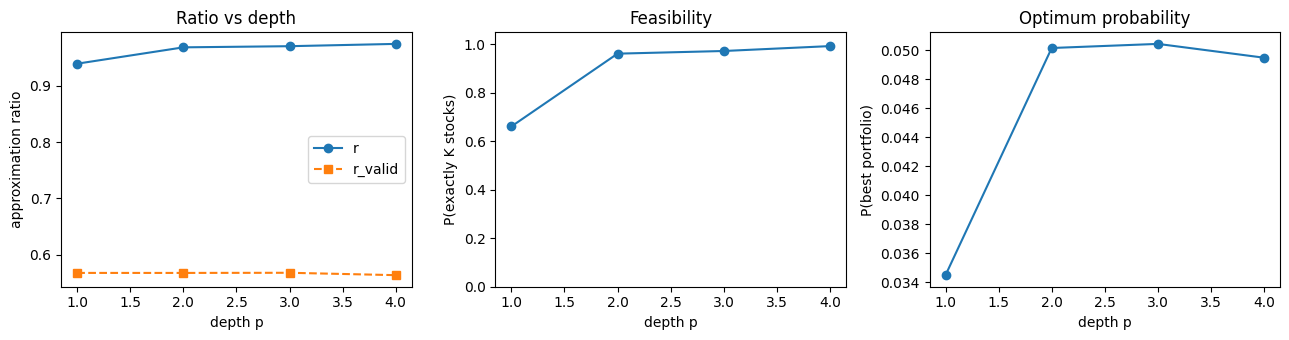

In [12]:
rows, best_params = [], {}
for p in range(1, 5):
    x, E = optimise(n, diag, p, restarts=20)
    best_params[p] = x
    m = metrics(P, LAM, x); m["p"] = p; rows.append(m)
    print(f"p={p}  <C>={m['E']:+.4f}  r={m['r']:.4f}  r_valid={m['r_valid']:.4f}  "
          f"P(feasible)={m['p_feasible']:.3f}  P(best)={m['p_best']:.3f}")

# Random-sampling baselines: any QAOA result must be judged against these
Cv = ref["C"][ref["valid"]]
print(f"baseline uniform over ALL 2^n bitstrings: r = {(ref['Cmax']-ref['C'].mean())/(ref['Cmax']-ref['Cmin']):.4f}")
print(f"baseline uniform over VALID portfolios:   r_valid = {(Cv.max()-Cv.mean())/(Cv.max()-Cv.min()):.4f}, P(best) = {1/ref['valid'].sum():.3f}")

ps = [m["p"] for m in rows]
fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
ax[0].plot(ps, [m["r"] for m in rows], "o-", label="r"); ax[0].plot(ps, [m["r_valid"] for m in rows], "s--", label="r_valid")
ax[0].set(xlabel="depth p", ylabel="approximation ratio", title="Ratio vs depth"); ax[0].legend()
ax[1].plot(ps, [m["p_feasible"] for m in rows], "o-"); ax[1].set(xlabel="depth p", ylabel="P(exactly K stocks)", ylim=(0, 1.05), title="Feasibility")
ax[2].plot(ps, [m["p_best"] for m in rows], "o-"); ax[2].set(xlabel="depth p", ylabel="P(best portfolio)", title="Optimum probability")
plt.tight_layout(); plt.savefig(f"{FIG}/baseline_depth_sweep.png", dpi=150, bbox_inches="tight"); plt.show()

**Reading the results.** With the penalty formulation QAOA quickly learns the budget rule (P(feasible) rises from about 0.66 at p=1 to about 0.99 at p=4) but not solution quality: P(best) ≈ 0.05 and r_valid ≈ 0.56 are what picking one of the 20 valid portfolios at random gives. The headline ratio r ≈ 0.97 looks impressive only because C_max is dominated by the penalty; uniform random sampling over all 2^n bitstrings already gives r ≈ 0.83.  
*(Exact values can differ slightly between SciPy versions, because COBYLA can end in different local optima; the conclusions do not change.)*

### 5b. Sweep the penalty $\lambda$
Fixed depth `p = 3`. For each $\lambda$ we re-optimise, then record the probability that a sample buys exactly `K` stocks and the probability of the single best valid portfolio. Also marked: the smallest $\lambda$ in the grid for which the *global* minimiser of $C$ is a valid portfolio.

lam=0.0   P(feasible)=0.006  P(best)=0.004  global min valid: False
lam=0.02  P(feasible)=0.008  P(best)=0.003  global min valid: False
lam=0.05  P(feasible)=0.123  P(best)=0.033  global min valid: False
lam=0.1   P(feasible)=0.364  P(best)=0.039  global min valid: False
lam=0.2   P(feasible)=0.795  P(best)=0.044  global min valid: True
lam=0.3   P(feasible)=0.913  P(best)=0.048  global min valid: True
lam=0.5   P(feasible)=0.973  P(best)=0.050  global min valid: True
lam=1.0   P(feasible)=0.994  P(best)=0.055  global min valid: True


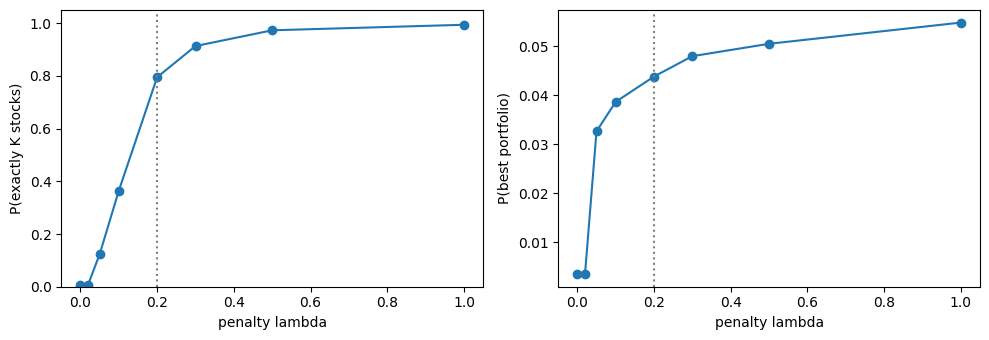

Smallest lambda in grid whose global minimiser is a valid portfolio: 0.2


In [13]:
lams = [0.0, 0.02, 0.05, 0.1, 0.2, 0.3, 0.5, 1.0]
sweep = []
for lam in lams:
    hh, JJ, oo = ising_coeffs(P, lam)
    dd = ising_diag(n, hh, JJ, oo)
    x, _ = optimise(n, dd, 3, restarts=10)
    m = metrics(P, lam, x)
    m["lam"] = lam; m["global_min_valid"] = classical_reference(P, lam)["global_min_is_valid"]
    sweep.append(m)
    print(f"lam={lam:<5} P(feasible)={m['p_feasible']:.3f}  P(best)={m['p_best']:.3f}  global min valid: {m['global_min_valid']}")

lam_safe = min((m["lam"] for m in sweep if m["global_min_valid"]), default=None)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(lams, [m["p_feasible"] for m in sweep], "o-"); ax[0].set(xlabel="penalty lambda", ylabel="P(exactly K stocks)", ylim=(0, 1.05))
ax[1].plot(lams, [m["p_best"] for m in sweep], "o-"); ax[1].set(xlabel="penalty lambda", ylabel="P(best portfolio)")
for a in ax:
    if lam_safe is not None: a.axvline(lam_safe, ls=":", c="gray")
plt.tight_layout(); plt.savefig(f"{FIG}/baseline_lambda_sweep.png", dpi=150, bbox_inches="tight"); plt.show()
print("Smallest lambda in grid whose global minimiser is a valid portfolio:", lam_safe)

**Reading the results.** For λ ≲ 0.02 almost every sample violates the budget (P(feasible) ≈ 0.01). It climbs to ≈ 0.36 at λ = 0.1, ≈ 0.79 at λ = 0.2 and above 0.97 for λ ≥ 0.5. On this instance the global minimiser of C is a valid portfolio only from λ ≈ 0.2 upward, so smaller penalties make QAOA's favourite answers break the budget. P(best) grows slowly with λ (≈ 0.004 up to ≈ 0.055) and only reaches the random-among-valid level (0.05) once λ is large: a bigger penalty buys feasibility, not quality.

## 6. [Qiskit] Sample the optimised circuit and compare with the reference

In [14]:
def decode(bitstring):                     # Qiskit prints qubit 0 on the right
    return tuple(int(c) for c in reversed(bitstring))

def sample(qc, gam, bet, params, shots=8192, seed=SEED):
    bound = bind(qc, gam, bet, params)
    bound.measure_all()
    return StatevectorSampler(seed=seed).run([bound], shots=shots).result()[0].data.meas.get_counts()

P_DEPTH = 3
qc, gam, bet = build_qaoa(n, h, J, P_DEPTH)
counts = sample(qc, gam, bet, best_params[P_DEPTH])
shots = sum(counts.values())
feasible = sum(c for s, c in counts.items() if sum(decode(s)) == K) / shots
best_hits = counts.get("".join(map(str, reversed(ref["xbest"]))), 0) / shots
print(f"sampled P(feasible)={feasible:.3f} vs exact {metrics(P, LAM, best_params[P_DEPTH])['p_feasible']:.3f}")
print(f"sampled P(best)    ={best_hits:.3f} vs exact {metrics(P, LAM, best_params[P_DEPTH])['p_best']:.3f}")
for s, c in sorted(counts.items(), key=lambda kv: -kv[1])[:5]:
    x = np.array(decode(s)); print(s, f"{c/shots:.3f}", "stocks", np.where(x)[0], f"cost={ref['C'][int(sum(b<<i for i,b in enumerate(x)))]:+.4f}")

sampled P(feasible)=0.970 vs exact 0.973
sampled P(best)    =0.052 vs exact 0.050
101010 0.053 stocks [1 3 5] cost=-0.4787
110100 0.052 stocks [2 4 5] cost=-0.4112
100110 0.052 stocks [1 2 5] cost=-0.5030
110001 0.050 stocks [0 4 5] cost=-0.3643
010101 0.049 stocks [0 2 4] cost=-0.3182


## 7. Scaling up: 12 stocks with a constraint-preserving QAOA
**Idea.** With the penalty formulation QAOA wastes amplitude on bitstrings that buy the wrong number of stocks and needs a tuned $\lambda$. Instead we (i) start in the **Dicke state** $|D^{n}_{K}\rangle$ (uniform superposition of all portfolios with exactly $K$ stocks), and (ii) use an **XY ring mixer**, which swaps a bought and an unbought stock and therefore never leaves the valid subspace. The cost then needs **no penalty** ($\lambda = 0$), so $\lambda$ disappears as a hyper-parameter.  
We compare against penalty QAOA, greedy selection, simulated annealing and brute force (924 valid portfolios).

In [15]:
P12 = make_problem(12, 6)
n12, K12 = P12["n"], P12["K"]
ref12 = classical_reference(P12, 0.0)            # at lam=0 the valid costs are the true portfolio costs
valid12 = ref12["valid"]
C12 = ref12["C"]                                  # cost of every bitstring (true objective, no penalty)
print("valid portfolios:", valid12.sum(), "(expect 924)")
print("optimal portfolio: stocks", np.where(ref12["xbest"])[0], f"cost = {ref12['Cmin_valid']:.4f}")

valid portfolios: 924 (expect 924)
optimal portfolio: stocks [ 1  5  6  8 10 11] cost = -1.0664


In [16]:
# ---- constraint-preserving QAOA, exact NumPy simulation (same circuit as the Qiskit version below) ----
def dicke_vector(n, K):
    v = np.zeros(2 ** n, complex)
    m = all_bitstrings(n).sum(1) == K
    v[m] = 1 / np.sqrt(m.sum())
    return v

def ring_matchings(n):                            # even n: two layers of disjoint edges
    return [[(i, i + 1) for i in range(0, n - 1, 2)], [(i, (i + 1) % n) for i in range(1, n, 2)]]

def pair_index(n, i, j):                          # index pairs (i=0,j=1) <-> (i=1,j=0)
    ks = np.arange(2 ** n)
    a = ks[(((ks >> i) & 1) == 0) & (((ks >> j) & 1) == 1)]
    return a, a ^ (1 << i) ^ (1 << j)

def make_xy_cache(n):
    return [[pair_index(n, i, j) for (i, j) in layer] for layer in ring_matchings(n)]

def cqaoa_state(n, K, diag, gammas, betas, cache, psi0=None):
    psi = dicke_vector(n, K) if psi0 is None else psi0.copy()
    for g, b in zip(gammas, betas):
        psi = psi * np.exp(-1j * g * diag)
        c, s = np.cos(b), np.sin(b)               # XXPlusYY(2b): exp(-i b (XX+YY)/2) on {|01>,|10>}
        for layer in cache:
            for a_idx, b_idx in layer:
                x, y = psi[a_idx], psi[b_idx]
                psi[a_idx], psi[b_idx] = c * x - 1j * s * y, -1j * s * x + c * y
    return psi

xy_cache12 = make_xy_cache(n12)
dicke12 = dicke_vector(n12, K12)
def c_energy(params, diag=C12, n=n12, K=K12, cache=xy_cache12):
    p = len(params) // 2
    psi = cqaoa_state(n, K, diag, params[:p], params[p:], cache, dicke12)
    return float(np.real(np.sum(np.abs(psi) ** 2 * diag)))

# sanity checks: norm preserved and all probability stays on valid portfolios
psi = cqaoa_state(n12, K12, C12, [0.7, 0.3], [0.4, 1.1], xy_cache12, dicke12)
print("norm:", np.linalg.norm(psi), " prob outside valid subspace:", float((np.abs(psi[~valid12]) ** 2).sum()))
assert abs(np.linalg.norm(psi) - 1) < 1e-10 and (np.abs(psi[~valid12]) ** 2).sum() < 1e-20

norm: 1.0000000000000007  prob outside valid subspace: 0.0


In [17]:
# ---- warm-start by interpolation (Zhou et al. 2020): build depth p+1 angles from the optimum at depth p ----
def interp_angles(x):
    p = len(x) // 2
    def f(a):
        A = np.r_[0.0, a, 0.0]
        return np.array([(i - 1) / p * A[i - 1] + (p - i + 1) / p * A[i] for i in range(1, p + 2)])
    return np.r_[f(x[:p]), f(x[p:])]

class Counter:                                     # counts energy evaluations (cost of the optimisation)
    def __init__(self, f): self.f, self.n = f, 0
    def __call__(self, x): self.n += 1; return self.f(x)

def local_opt(f, x0, maxiter=300):
    fc = Counter(f)
    res = minimize(fc, x0, method="COBYLA", options={"maxiter": maxiter})
    return res.x, res.fun, fc.n

def multistart(f, p, restarts, seed=0, maxiter=300):
    rng = np.random.default_rng(seed); best, total = None, 0
    for _ in range(restarts):
        x, e, k = local_opt(f, rng.uniform(0, np.pi / 2, 2 * p), maxiter); total += k
        if best is None or e < best[1]: best = (x, e)
    return best[0], best[1], total

PMAX = 5
cons = {"interp": {}, "random": {}}
# interpolation strategy: multistart only at p=1, then one local run per deeper layer
x, e, k = multistart(c_energy, 1, 10)
cons["interp"][1] = (x, e, k)
for p in range(2, PMAX + 1):
    x0 = interp_angles(cons["interp"][p - 1][0])
    x, e, k = local_opt(c_energy, x0)
    cons["interp"][p] = (x, e, k)
# baseline strategy: independent random multistart at every depth (same total budget order of magnitude)
for p in range(1, PMAX + 1):
    cons["random"][p] = multistart(c_energy, p, 8, seed=p)
for p in range(1, PMAX + 1):
    print(f"p={p}  interp: <C>={cons['interp'][p][1]:+.4f} ({cons['interp'][p][2]:4d} evals)   "
          f"random multistart: <C>={cons['random'][p][1]:+.4f} ({cons['random'][p][2]:4d} evals)")

p=1  interp: <C>=-0.8270 (3000 evals)   random multistart: <C>=-0.8271 (2400 evals)
p=2  interp: <C>=-0.8699 ( 300 evals)   random multistart: <C>=-0.8435 (2400 evals)
p=3  interp: <C>=-0.8946 ( 300 evals)   random multistart: <C>=-0.8532 (2400 evals)
p=4  interp: <C>=-0.9078 ( 300 evals)   random multistart: <C>=-0.8514 (2400 evals)
p=5  interp: <C>=-0.9198 ( 300 evals)   random multistart: <C>=-0.8676 (2400 evals)


In [18]:
# ---- metrics on the valid subspace, plus the penalty-QAOA comparison on the same 12-stock problem ----
Cv12 = C12[valid12]
order = np.argsort(np.where(valid12, C12, np.inf))[:5]            # indices of the 5 best valid portfolios
def stats_from_prob(prob):
    pf = float(prob[valid12].sum())
    Ef = float(prob[valid12] @ Cv12 / pf)
    return dict(p_feasible=pf, p_best=float(prob[ref12["kbest"]]), p_top5=float(prob[order].sum()),
                E=Ef, r_valid=(Cv12.max() - Ef) / (Cv12.max() - Cv12.min()))

def cons_stats(x):
    p = len(x) // 2
    psi = cqaoa_state(n12, K12, C12, x[:p], x[p:], xy_cache12, dicke12)
    return stats_from_prob(np.abs(psi) ** 2)

# penalty QAOA at the smallest lambda (from a coarse grid) whose global minimiser is a valid portfolio
lam12 = next(l for l in [0.05, 0.1, 0.2, 0.3, 0.5, 1.0] if classical_reference(P12, l)["global_min_is_valid"])
h12, J12, off12 = ising_coeffs(P12, lam12)
diag12 = ising_diag(n12, h12, J12, off12)
pen = {}
for p in range(1, 4):                                              # n=12 full-space simulation, kept to p<=3 for runtime
    x, e = optimise(n12, diag12, p, restarts=6, maxiter=300)
    prob = np.abs(qaoa_state(n12, diag12, x[:p], x[p:])) ** 2
    pen[p] = stats_from_prob(prob)

print(f"uniform over valid portfolios: P(best)={1/valid12.sum():.4f}  r_valid={(Cv12.max()-Cv12.mean())/(Cv12.max()-Cv12.min()):.4f}")
print(f"penalty QAOA (lam={lam12}):")
for p, m in pen.items():
    print(f"  p={p}  P(feasible)={m['p_feasible']:.3f}  P(best)={m['p_best']:.4f}  P(top5)={m['p_top5']:.4f}  r_valid={m['r_valid']:.4f}")
print("constraint-preserving QAOA (Dicke + XY ring, no penalty), interpolated angles:")
cons_m = {}
for p in range(1, PMAX + 1):
    cons_m[p] = cons_stats(cons["interp"][p][0])
    m = cons_m[p]
    print(f"  p={p}  P(feasible)={m['p_feasible']:.3f}  P(best)={m['p_best']:.4f}  P(top5)={m['p_top5']:.4f}  r_valid={m['r_valid']:.4f}")

uniform over valid portfolios: P(best)=0.0011  r_valid=0.4592
penalty QAOA (lam=0.2):
  p=1  P(feasible)=0.540  P(best)=0.0008  P(top5)=0.0038  r_valid=0.4791
  p=2  P(feasible)=0.621  P(best)=0.0011  P(top5)=0.0052  r_valid=0.4921
  p=3  P(feasible)=0.627  P(best)=0.0014  P(top5)=0.0066  r_valid=0.5108
constraint-preserving QAOA (Dicke + XY ring, no penalty), interpolated angles:
  p=1  P(feasible)=1.000  P(best)=0.0120  P(top5)=0.0509  r_valid=0.6939
  p=2  P(feasible)=1.000  P(best)=0.0262  P(top5)=0.1096  r_valid=0.7488
  p=3  P(feasible)=1.000  P(best)=0.0527  P(top5)=0.1805  r_valid=0.7804
  p=4  P(feasible)=1.000  P(best)=0.0591  P(top5)=0.1930  r_valid=0.7973
  p=5  P(feasible)=1.000  P(best)=0.0722  P(top5)=0.1921  r_valid=0.8126


In [19]:
# ---- classical baselines on the same 12-stock problem (greedy, simulated annealing) ----
mu12, sig12, q12 = P12["mu"], P12["sigma"], P12["q"]
f_port = lambda x: q12 * x @ sig12 @ x - mu12 @ x

def greedy(K):
    x = np.zeros(n12)
    for _ in range(K):
        gains = [(f_port(np.where(np.arange(n12) == i, 1.0, x)) if x[i] == 0 else np.inf, i) for i in range(n12)]
        x[min(gains)[1]] = 1.0
    return x

def simulated_annealing(K, rng, steps=3000, T0=0.05, T1=1e-4):
    x = np.zeros(n12); x[rng.choice(n12, K, replace=False)] = 1.0
    fx = f_port(x); best, fbest = x.copy(), fx
    for t in range(steps):
        T = T0 * (T1 / T0) ** (t / steps)
        i, j = rng.choice(np.where(x == 1)[0]), rng.choice(np.where(x == 0)[0])      # swap move keeps exactly K stocks
        y = x.copy(); y[i], y[j] = 0.0, 1.0
        fy = f_port(y)
        if fy < fx or rng.random() < np.exp(-(fy - fx) / T):
            x, fx = y, fy
            if fx < fbest: best, fbest = x.copy(), fx
    return best, fbest

opt = ref12["Cmin_valid"]
xg = greedy(K12); fg = f_port(xg)
rng = np.random.default_rng(SEED)
sa = [simulated_annealing(K12, rng)[1] for _ in range(20)]
print(f"optimum (brute force)  : {opt:.4f}")
print(f"greedy                 : {fg:.4f}  (gap {fg - opt:.4f}, optimal: {abs(fg - opt) < 1e-9})")
print(f"simulated annealing x20: best {min(sa):.4f}, hit optimum in {sum(abs(s - opt) < 1e-9 for s in sa)}/20 runs")

optimum (brute force)  : -1.0664
greedy                 : -1.0664  (gap 0.0000, optimal: True)
simulated annealing x20: best -1.0664, hit optimum in 20/20 runs


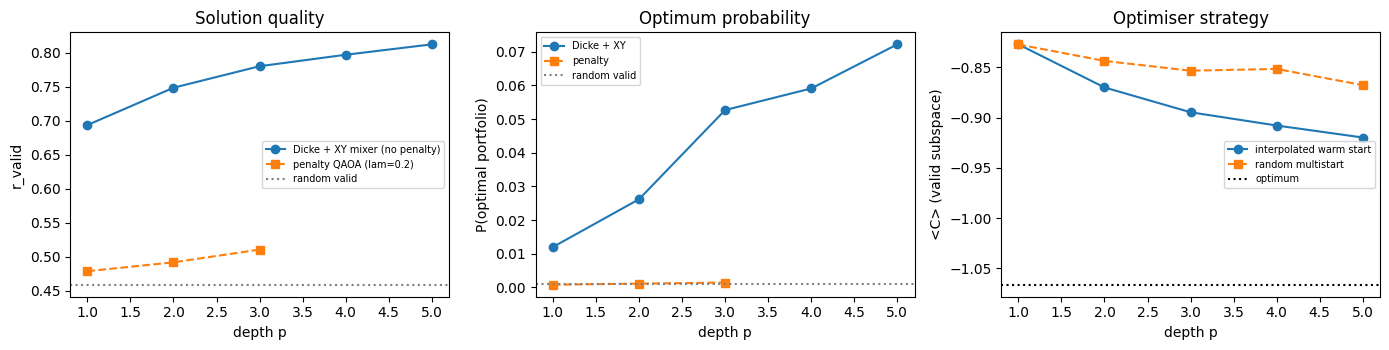

In [20]:
# ---- summary figure ----
ps = list(range(1, PMAX + 1))
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(ps, [cons_m[p]["r_valid"] for p in ps], "o-", label="Dicke + XY mixer (no penalty)")
ax[0].plot(list(pen), [pen[p]["r_valid"] for p in pen], "s--", label=f"penalty QAOA (lam={lam12})")
ax[0].axhline((Cv12.max() - Cv12.mean()) / (Cv12.max() - Cv12.min()), c="gray", ls=":", label="random valid")
ax[0].set(xlabel="depth p", ylabel="r_valid", title="Solution quality"); ax[0].legend(fontsize=7)
ax[1].plot(ps, [cons_m[p]["p_best"] for p in ps], "o-", label="Dicke + XY"); ax[1].plot(list(pen), [pen[p]["p_best"] for p in pen], "s--", label="penalty")
ax[1].axhline(1 / valid12.sum(), c="gray", ls=":", label="random valid"); ax[1].set(xlabel="depth p", ylabel="P(optimal portfolio)", title="Optimum probability"); ax[1].legend(fontsize=7)
ax[2].plot(ps, [cons["interp"][p][1] for p in ps], "o-", label="interpolated warm start")
ax[2].plot(ps, [cons["random"][p][1] for p in ps], "s--", label="random multistart")
ax[2].axhline(opt, c="k", ls=":", label="optimum"); ax[2].set(xlabel="depth p", ylabel="<C> (valid subspace)", title="Optimiser strategy"); ax[2].legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{FIG}/scaling_12_stocks.png", dpi=150, bbox_inches="tight"); plt.show()

**Reading the results.** The Dicke start with an XY ring mixer keeps all probability on valid portfolios and needs no λ. P(best) grows with depth, from ≈ 0.012 at p=1 to ≈ 0.07 at p=5 (about 65× the 0.0011 of a random valid portfolio), and r_valid rises from ≈ 0.69 to ≈ 0.81. Penalty QAOA at p=3 reaches only r_valid ≈ 0.51 (random: 0.46) with about 63% feasible samples. Starting each depth from the interpolated angles of the previous one reaches lower energy than random restarts at every p ≥ 2, with 300 energy evaluations per extra depth instead of 2400 (the 3000 evaluations at p=1 are a one-off cost).  
Greedy selection and simulated annealing both find the exact optimum on this instance, so **there is no quantum advantage here**: the value of the experiment is in showing how the problem structure (a hard constraint) is best handled in the circuit rather than in the cost function.

### 7b. [Qiskit] The same constraint-preserving circuit
`StatePreparation` loads the Dicke state exactly (fine for simulation; it is **deep**, so for hardware replace it with a linear-depth Dicke circuit, see section 8). The XY mixer uses `XXPlusYYGate(2*beta)`, which acts as $e^{-i\beta (XX+YY)/2}$ and matches the NumPy simulation above. Cross-check at random angles before trusting any Qiskit number.

In [21]:
from qiskit.circuit.library import XXPlusYYGate, StatePreparation

def build_constrained_qaoa(n, K, h, J, p):
    gam, bet = ParameterVector("gam", p), ParameterVector("bet", p)
    qc = QuantumCircuit(n)
    qc.append(StatePreparation(dicke_vector(n, K)), range(n))
    for l in range(p):
        for (i, j), v in J.items():
            qc.rzz(2 * gam[l] * float(v), i, j)
        for i in range(n):
            qc.rz(2 * gam[l] * float(h[i]), i)
        for layer in ring_matchings(n):
            for (i, j) in layer:
                qc.append(XXPlusYYGate(2 * bet[l]), [i, j])
    return qc, gam, bet

h0, J0, off0 = ising_coeffs(P12, 0.0)                    # lam = 0: the constraint is enforced by the circuit
H12 = build_cost_operator(n12, h0, J0)
assert np.allclose(np.real(np.diag(H12.to_matrix())) + off0, C12)
rng = np.random.default_rng(3)
for p in (1, 2, 3):
    qcc, gam_c, bet_c = build_constrained_qaoa(n12, K12, h0, J0, p)
    prm = rng.uniform(0, np.pi, 2 * p)
    e_q = qiskit_energy(qcc, gam_c, bet_c, prm, H12, off0)
    e_np = c_energy(prm)
    print(f"p={p}: qiskit={e_q:.8f}  numpy={e_np:.8f}  diff={abs(e_q - e_np):.2e}")
    assert abs(e_q - e_np) < 1e-8

p=1: qiskit=-0.63697539  numpy=-0.63697539  diff=1.07e-14
p=2: qiskit=-0.63781778  numpy=-0.63781778  diff=3.55e-15
p=3: qiskit=-0.64126193  numpy=-0.64126193  diff=1.11e-15


## 8. Limitations and future work
- **Scale and advantage.** Both instances (6 and 12 qubits) are simulated exactly. Classical greedy and simulated annealing solve them optimally, and QAOA at p ≤ 5 finds the best portfolio with probability of at most about 7%. No claim of quantum advantage is made.
- **Optimiser sensitivity.** COBYLA can end in different local optima (results shift slightly between environments). A more rigorous study would repeat each experiment over many seeds and report mean and spread.
- **No noise or hardware runs.** Everything here is ideal simulation. The Dicke state is loaded with `StatePreparation`, which is exact but very deep on a real device, and the XY mixer adds routing depth on heavy-hex hardware. Next steps: a linear-depth Dicke circuit (Bärtschi and Eidenbenz), transpilation depth and gate-count reports, noisy simulation, and error suppression/mitigation on a real backend.
- **Harder instances.** 20+ assets, extra constraints (e.g. a cap per sector), and the training problems that come with scale (barren plateaus).

## References
- Farhi, Goldstone, Gutmann, *A Quantum Approximate Optimization Algorithm*, arXiv:1411.4028
- Hadfield et al., *From the Quantum Approximate Optimization Algorithm to a Quantum Alternating Operator Ansatz*, arXiv:1709.03489
- Bärtschi, Eidenbenz, *Deterministic Preparation of Dicke States*, arXiv:1904.07358
- Zhou et al., *Quantum Approximate Optimization Algorithm: Performance, Mechanism, and Implementation on Near-Term Devices*, arXiv:1812.01041
- Sachdeva et al., *Quantum optimization using a 127-qubit gate-model IBM quantum computer can outperform quantum annealers for nontrivial binary optimization problems*, arXiv:2406.01743